# COGS 108 - Playoff Data Cleaning

Runs after the regular-season cleaning notebook, which saves `data/02-processed/nba_regular_season_cleaned.csv`.

In [1]:
%pip install duckdb

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import urllib.request
import pandas as pd

os.makedirs('data/00-raw', exist_ok=True)

reg_path = 'data/00-raw/nba_regular_season_2016_2026.csv'
po_path = 'data/00-raw/nba_playoffs_2016_2026.csv'

DB_URL = "https://basketball-data.billmill.org/nba/nba.duckdb"

def fetch_nba_dataset(con, season_type):
    """season_type: 'regular_season' or 'playoffs'. Returns one row per player-season (2015-16 to 2025-26)."""
    query = f"""
    WITH first_season AS (
        -- each player's first regular-season year in the DB (same for both tables)
        SELECT player_id, MIN(season) AS first_season
        FROM player_season_stats_per_game
        WHERE season_type = 'regular_season'
        GROUP BY player_id
    ),
    dedup_stats AS (
        SELECT
            s.player_id,
            p.name AS player_name,
            s.season,
            MAX(s.age) AS age,
            -- rookie season = 1. Drafted: season - draft_year. Undrafted: counted from first regular season.
            s.season - COALESCE(MAX(s.draft_year), MAX(f.first_season) - 1) AS years_in_nba,
            MAX(s.draft_year) IS NULL AS years_in_nba_estimated,
            SUM(s.gp) AS gp,
            SUM(s.min * s.gp) / NULLIF(SUM(s.gp), 0) AS mpg,
            SUM(s.pts * s.gp) / NULLIF(SUM(s.gp), 0) AS ppg,
            SUM(s.reb * s.gp) / NULLIF(SUM(s.gp), 0) AS rpg,
            SUM(s.ast * s.gp) / NULLIF(SUM(s.gp), 0) AS apg,
            SUM(s.blk * s.gp) / NULLIF(SUM(s.gp), 0) AS bpg,
            SUM(s.stl * s.gp) / NULLIF(SUM(s.gp), 0) AS spg,
            SUM(s.plus_minus * s.gp) / NULLIF(SUM(s.gp), 0) AS plus_minus,
            SUM(s.ts_pct * s.gp) / NULLIF(SUM(s.gp), 0) AS ts_pct
        FROM player_season_stats_per_game s
        JOIN players p ON s.player_id = p.player_id
        LEFT JOIN first_season f ON s.player_id = f.player_id
        WHERE s.season BETWEEN 2014 AND 2026
          AND s.season_type = '{season_type}'
        GROUP BY s.player_id, p.name, s.season
    ),
    with_trends AS (
        SELECT
            *,
            (COUNT(*) OVER w3 = 3 AND MAX(season) OVER w3 - MIN(season) OVER w3 = 2) AS full_3yr_window,
            AVG(ppg) OVER w3 AS trend_3yr_ppg,
            AVG(rpg) OVER w3 AS trend_3yr_rpg,
            AVG(apg) OVER w3 AS trend_3yr_apg,
            AVG(plus_minus) OVER w3 AS trend_3yr_pm,
            AVG(mpg) OVER w3 AS trend_3yr_mpg,
            AVG(gp) OVER w3 AS trend_3yr_gp
        FROM dedup_stats
        WINDOW w3 AS (
            PARTITION BY player_id
            ORDER BY season
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        )
    )
    SELECT
        season, player_id, player_name, age, years_in_nba, years_in_nba_estimated, gp,
        ROUND(mpg, 2) AS mpg, ROUND(ppg, 2) AS ppg, ROUND(rpg, 2) AS rpg,
        ROUND(apg, 2) AS apg, ROUND(bpg, 2) AS bpg, ROUND(spg, 2) AS spg,
        ROUND(plus_minus, 2) AS plus_minus, ROUND(ts_pct, 4) AS ts_pct,
        full_3yr_window,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_ppg, 2) END AS trend_3yr_ppg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_rpg, 2) END AS trend_3yr_rpg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_apg, 2) END AS trend_3yr_apg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_pm, 2) END AS trend_3yr_pm,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_mpg, 2) END AS trend_3yr_mpg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_gp, 2) END AS trend_3yr_gp
    FROM with_trends
    WHERE season BETWEEN 2016 AND 2026
    ORDER BY season DESC, ppg DESC;
    """
    return con.sql(query).df()

def build_csvs():
    """Only runs when the CSVs are missing: download the database temporarily, save the CSVs, delete the database."""
    import duckdb
    
    tmp_db = 'nba_tmp.duckdb'
    print('CSV files not found. Downloading the database once (it is deleted afterwards)...')
    urllib.request.urlretrieve(DB_URL, tmp_db)
    con = duckdb.connect(tmp_db, read_only=True)
    try:
        print(con.sql("DESCRIBE player_season_stats_per_game").df()[['column_name', 'column_type']])
        fetch_nba_dataset(con, 'regular_season').to_csv(reg_path, index=False)
        fetch_nba_dataset(con, 'playoffs').to_csv(po_path, index=False)
    finally:
        con.close()
        os.remove(tmp_db)

if not (os.path.exists(reg_path) and os.path.exists(po_path)):
    build_csvs()

df_regular = pd.read_csv(reg_path)
df_playoffs = pd.read_csv(po_path)
print(df_regular.shape, df_playoffs.shape)
print(df_regular['years_in_nba'].isna().sum(), df_playoffs['years_in_nba'].isna().sum())



(5968, 22) (2405, 22)
0 1


In [3]:
# Setup: helpers and the cleaned regular-season table from the regular-season notebook
# (copied unchanged from that notebook so this one runs on its own)
import os
import pandas as pd
import matplotlib.pyplot as plt

def flag_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return (series < lower_bound) | (series > upper_bound)

def get_season_label(year):
    start_yr = year - 1
    return f"{start_yr}-{str(year)[-2:]}"

column_order = [
    'season_label', 'season', 'player_id', 'player_name', 'age',
    'years_in_nba', 'years_in_nba_estimated', 'gp', 'mpg', 'ppg',
    'rpg', 'apg', 'bpg', 'spg', 'plus_minus', 'ts_pct',
    'full_3yr_window', 'trend_3yr_ppg', 'trend_3yr_rpg', 'trend_3yr_apg',
    'trend_3yr_pm', 'trend_3yr_mpg', 'trend_3yr_gp', 'ppg_outlier', 'suspicious_entry'
]
stat_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'plus_minus', 'ts_pct', 'age', 'years_in_nba']

# Saved by the regular-season cleaning notebook; used only for the regular season vs playoffs comparison
os.makedirs('data/02-processed', exist_ok=True)
df_regular_clean = pd.read_csv('data/02-processed/nba_regular_season_cleaned.csv')
print(df_regular_clean.shape)

(5254, 25)


##  Playoffs
We repeat the regular-season steps (3B–4) on `df_playoffs`, which was loaded in the first cell.
Playoff samples are much smaller (a team plays 4 to 28 games), so a few thresholds are different:

| Check | Regular season | Playoffs | Why |
|---|---|---|---|
| Minimum games | `gp >= 10` | `gp >= 4` | 4 games = one full series (a sweep). 10 would drop most first-round players |
| Too many games | `gp > 82` | `gp > 28` | 4 rounds × 7 games is the most possible |

Play-in games are **not** in this table: the database has only `regular_season` and `playoffs`, and players whose
teams lost in the play-in (e.g. Stephen Curry and DeMar DeRozan in 2023-24) have no playoff row.

### Is the playoff data tidy?
Same checks as 3B: one row per player-season, data types, lowercase column names.

In [4]:
print("--- Dataframe Info ---")
df_playoffs.info()

po_duplicate_pairs = df_playoffs.duplicated(subset=['player_id', 'season']).sum()
print(f"\nNumber of duplicate (player_id, season) pairs: {po_duplicate_pairs}")

po_columns_are_lowercase = df_playoffs.columns.tolist() == [c.lower() for c in df_playoffs.columns]
print(f"Are all columns lowercase? {po_columns_are_lowercase}")
if not po_columns_are_lowercase:
    df_playoffs.columns = [c.lower() for c in df_playoffs.columns]
    print("Converted columns to lowercase.")

--- Dataframe Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2405 entries, 0 to 2404
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   season                  2405 non-null   int64  
 1   player_id               2405 non-null   int64  
 2   player_name             2405 non-null   str    
 3   age                     2405 non-null   float64
 4   years_in_nba            2404 non-null   float64
 5   years_in_nba_estimated  2405 non-null   bool   
 6   gp                      2405 non-null   float64
 7   mpg                     2405 non-null   float64
 8   ppg                     2405 non-null   float64
 9   rpg                     2405 non-null   float64
 10  apg                     2405 non-null   float64
 11  bpg                     2405 non-null   float64
 12  spg                     2405 non-null   float64
 13  plus_minus              2405 non-null   float64
 14  ts_pct                  2405

### What we found
* **Tidiness:** The data is tidy. Each row is one player's stats for one postseason, and each column is one attribute.
* **Duplicates:** There are 0 duplicate (player_id, season) pairs, so each player has at most one playoff record per season.
* **Column names:** The column names are already lowercase and match the regular-season table, so the two tables can be compared directly.

### Playoffs: Size of the data

In [5]:
po_rows, po_cols = df_playoffs.shape
print(f"Dataset Shape: {po_rows} rows, {po_cols} columns")
print(f"Season Range: {df_playoffs['season'].min()} to {df_playoffs['season'].max()}")
print(f"Number of Unique Players: {df_playoffs['player_id'].nunique()}")
print("\nRows per Season (expect roughly 200-240: 16 teams x 13-15 players):")
print(df_playoffs['season'].value_counts().sort_index())
print(f"\nGames Played (gp) - Min: {df_playoffs['gp'].min()}, "
      f"Median: {df_playoffs['gp'].median()}, Max: {df_playoffs['gp'].max()}")

# How many playoff players also have a regular-season row that season?
po_in_reg = df_playoffs.merge(df_regular[['player_id', 'season']].drop_duplicates(),
                              on=['player_id', 'season'], how='left', indicator=True)
print("\nPlayoff rows with a matching regular-season row:")
print(po_in_reg['_merge'].map({'both': 'yes', 'left_only': 'no'}).value_counts())

Dataset Shape: 2405 rows, 22 columns
Season Range: 2016 to 2026
Number of Unique Players: 864

Rows per Season (expect roughly 200-240: 16 teams x 13-15 players):
season
2016    215
2017    215
2018    210
2019    212
2020    217
2021    239
2022    217
2023    217
2024    214
2025    219
2026    230
Name: count, dtype: int64

Games Played (gp) - Min: 1.0, Median: 6.0, Max: 24.0

Playoff rows with a matching regular-season row:
_merge
yes    2398
no        7
Name: count, dtype: int64


### What we found
* **Rows and columns:** The raw playoff table has 2,405 rows and 22 columns, about 40% of the size of the regular-season table (5,968 rows). That's expected, because only 16 of 30 teams make the playoffs.
* **Seasons and players:** It covers 2016 to 2026 (2015-16 to 2025-26) with 864 different players. Each postseason has between 210 and 239 players, which fits 16 teams with 13 to 15 players each.
* **Games played:** Players played from 1 to 24 playoff games, and the middle value is 6, compared with 53 in the regular season. Playoff samples are much smaller, which is why we use a lower games cutoff in 5E.
* **Matching regular-season rows:** 2,398 playoff rows have a regular-season row for the same player and season. The other 7 don't, so those players appear only in the playoff table that year.

### Playoffs: Missing data analysis
Trend columns are expected to be missing more often than in the regular season: a playoff trend needs
**three postseasons in a row**, which only players on consistently good teams have.

In [6]:
print("--- Missing values per column ---")
print(df_playoffs.isna().sum())

print(f"\nRows with gp == 0: {(df_playoffs['gp'] == 0).sum()}")
print(f"Rows with mpg == 0: {(df_playoffs['mpg'] == 0).sum()}")

po_no_window = (~df_playoffs['full_3yr_window']).sum()
print(f"Rows where full_3yr_window is False: {po_no_window} "
      f"({po_no_window / len(df_playoffs):.1%} of playoff rows)")
print(f"Rows where trend_3yr_ppg is NaN: {df_playoffs['trend_3yr_ppg'].isna().sum()}")

po_non_trend_nans = df_playoffs.drop(columns=[c for c in df_playoffs.columns if 'trend_3yr' in c]).isna().sum()
print("\nMissing values outside the trend columns:")
print(po_non_trend_nans[po_non_trend_nans > 0])
display(df_playoffs[df_playoffs['years_in_nba'].isna()][['season', 'player_id', 'player_name', 'age', 'years_in_nba']])

--- Missing values per column ---
season                       0
player_id                    0
player_name                  0
age                          0
years_in_nba                 1
years_in_nba_estimated       0
gp                           0
mpg                          0
ppg                          0
rpg                          0
apg                          0
bpg                          0
spg                          0
plus_minus                   0
ts_pct                       0
full_3yr_window              0
trend_3yr_ppg             1685
trend_3yr_rpg             1685
trend_3yr_apg             1685
trend_3yr_pm              1685
trend_3yr_mpg             1685
trend_3yr_gp              1685
dtype: int64

Rows with gp == 0: 0
Rows with mpg == 0: 1
Rows where full_3yr_window is False: 1685 (70.1% of playoff rows)
Rows where trend_3yr_ppg is NaN: 1685

Missing values outside the trend columns:
years_in_nba    1
dtype: int64


,season,player_id,player_name,age,years_in_nba
1077,2022,1630492,Luca Vildoza,26.0,NaN


### What we found
* **Trend columns:** 1,685 rows (70%) have no 3-season trend, compared with 37% in the regular season. A playoff trend needs **three postseasons in a row**, and most players' teams don't make the playoffs three years running, so these blanks are expected and left as is.
* **Other missing values:** Only `years_in_nba`, for 1 row: Luca Vildoza in 2021-22. It's handled in 5E.
* **Zero games or minutes:** No row has 0 games, and 1 row has 0 minutes per game. That row is removed by the games filter in 5E.

### Playoffs: Outliers and suspicious entries
Same IQR rule as 3E (`flag_iqr`, defined earlier), applied within each postseason.

In [7]:
po_ppg_outlier_series = df_playoffs.groupby('season')['ppg'].transform(flag_iqr)
po_mpg_outlier_series = df_playoffs.groupby('season')['mpg'].transform(flag_iqr)
print(f"Total ppg outliers across all postseasons: {po_ppg_outlier_series.sum()}")
print(f"Total mpg outliers across all postseasons: {po_mpg_outlier_series.sum()}")

print(f"ts_pct outside 0-1: {((df_playoffs['ts_pct'] < 0) | (df_playoffs['ts_pct'] > 1)).sum()}")
print(f"ts_pct == 0: {(df_playoffs['ts_pct'] == 0).sum()}")
print(f"gp > 28: {(df_playoffs['gp'] > 28).sum()}")
po_neg_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp']
print(f"Negative values in stats: {(df_playoffs[po_neg_cols] < 0).sum().sum()}")
print(f"Impossible age or experience: "
      f"{((df_playoffs['age'] < 18) | (df_playoffs['years_in_nba'] < 1)).sum()}")

print("\n--- Top 10 ppg Outliers ---")
display(df_playoffs[po_ppg_outlier_series][['season', 'player_name', 'ppg', 'mpg', 'gp']]
        .sort_values('ppg', ascending=False).head(10))

print("\n--- Examples of Suspicious Rows (gp > 28 or ts_pct == 0 or ts_pct > 1) ---")
display(df_playoffs[(df_playoffs['gp'] > 28) | (df_playoffs['ts_pct'] == 0) | (df_playoffs['ts_pct'] > 1)].head(5))

Total ppg outliers across all postseasons: 64
Total mpg outliers across all postseasons: 0
ts_pct outside 0-1: 23
ts_pct == 0: 154
gp > 28: 0
Negative values in stats: 0
Impossible age or experience: 1

--- Top 10 ppg Outliers ---


,season,player_name,ppg,mpg,gp
1975,2017,Russell Westbrook,37.40,38.90,5.0
1336,2020,Donovan Mitchell,36.29,37.66,7.0
1097,2021,Luka Dončić,35.71,40.15,7.0
663,2023,Kawhi Leonard,34.50,40.19,2.0
1098,2021,Damian Lillard,34.33,41.32,6.0
1099,2021,Kevin Durant,34.25,40.41,12.0
1765,2018,LeBron James,34.00,41.89,22.0
664,2023,Devin Booker,33.73,41.70,11.0
449,2024,Joel Embiid,33.00,41.38,6.0
230,2025,Giannis Antetokounmpo,33.00,37.57,5.0



--- Examples of Suspicious Rows (gp > 28 or ts_pct == 0 or ts_pct > 1) ---


,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,rpg,...,spg,plus_minus,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp
109,2026,1642859,Jase Richardson,20.0,1.0,False,1.0,2.95,6.0,0.0,...,0.0,3.00,1.500,False,NaN,NaN,NaN,NaN,NaN,NaN
117,2026,1630192,Zeke Nnaji,25.0,6.0,False,2.0,9.53,5.0,1.5,...,0.5,-1.50,1.078,True,2.61,1.11,0.28,-2.11,6.64,3.67
200,2026,1631120,JD Davison,23.0,4.0,False,2.0,2.62,1.0,1.0,...,0.0,0.50,1.136,False,NaN,NaN,NaN,NaN,NaN,NaN
217,2026,200768,Kyle Lowry,40.0,20.0,False,2.0,1.38,0.0,0.5,...,0.0,-1.50,0.000,False,NaN,NaN,NaN,NaN,NaN,NaN
218,2026,1642346,Ryan Dunn,23.0,2.0,False,4.0,8.45,0.0,1.5,...,0.0,-2.25,0.000,False,NaN,NaN,NaN,NaN,NaN,NaN


### What we found
* **Scoring outliers:** The IQR rule flags 64 player-postseasons for `ppg` and 0 for `mpg`. The highest is Russell Westbrook in 2016-17 (37.40 points per game over 5 games). Several of the top outliers come from short playoff runs (Kawhi Leonard's 34.50 in 2022-23 is over only 2 games), so playoff scoring outliers are partly a small-sample effect. They're real performances, so we keep them and only flag them.
* **Suspicious entries:** 177 rows have a `ts_pct` of 0 or above 1. 153 of them are players with fewer than 4 games and are removed by the `gp >= 4` filter in 5E. The other 24 stay in the table and are marked in `suspicious_entry`. No row has more than 28 games.
* **No other problems:** No stat is negative. 1 row has an impossible age or years in the NBA, and it is removed by the games filter in 5E (the cleaned table's minimum is 1 year).

### Playoffs: Clean the playoff data
Same steps as 3F, plus filling the missing `years_in_nba` from that player's regular-season row.

In [8]:
PO_MIN_GP = 4      # one full series

df_playoffs_clean = df_playoffs.copy()
print(f"Initial clean row count: {len(df_playoffs_clean)}")

# 1. Add season_label (same helper as 3F)
df_playoffs_clean['season_label'] = df_playoffs_clean['season'].apply(get_season_label)
print(f"Step 1 - Added season_label. Row count: {len(df_playoffs_clean)}")

# 2. Fill missing years_in_nba from the regular-season table
po_missing_before = df_playoffs_clean['years_in_nba'].isna().sum()
reg_years = df_regular.set_index(['player_id', 'season'])['years_in_nba']
fill_values = pd.Series(
    [reg_years.get((p, s)) for p, s in zip(df_playoffs_clean['player_id'], df_playoffs_clean['season'])],
    index=df_playoffs_clean.index, dtype='float')
df_playoffs_clean['years_in_nba'] = df_playoffs_clean['years_in_nba'].fillna(fill_values)
po_missing_after = df_playoffs_clean['years_in_nba'].isna().sum()
print(f"Step 2 - Filled years_in_nba: {po_missing_before} missing before, {po_missing_after} after.")
if po_missing_after > 0:
    # Undrafted AND no regular-season row that season, so there's nothing to fill from. Leave blank, mark estimated.
    still_missing = df_playoffs_clean['years_in_nba'].isna()
    df_playoffs_clean.loc[still_missing, 'years_in_nba_estimated'] = True
    print("         Still missing (no regular-season row to copy from):")
    display(df_playoffs_clean.loc[still_missing, ['season', 'player_id', 'player_name', 'gp']])
df_playoffs_clean['years_in_nba'] = df_playoffs_clean['years_in_nba'].astype('Int64')

# 3. Filter for gp >= PO_MIN_GP
initial_count = len(df_playoffs_clean)
df_playoffs_clean = df_playoffs_clean[df_playoffs_clean['gp'] >= PO_MIN_GP]
removed_count = initial_count - len(df_playoffs_clean)
print(f"Step 3 - Kept gp >= {PO_MIN_GP}. Removed {removed_count} rows "
      f"({removed_count / initial_count * 100:.2f}% of the table). Row count: {len(df_playoffs_clean)}")

# 4. Add ppg_outlier (recalculated on the filtered table)
df_playoffs_clean['ppg_outlier'] = df_playoffs_clean.groupby('season')['ppg'].transform(flag_iqr)
print(f"Step 4 - Recalculated ppg_outlier. Row count: {len(df_playoffs_clean)}")

# 5. Label suspicious entries
po_susp_mask = (
    (df_playoffs_clean['ts_pct'] < 0) |
    (df_playoffs_clean['ts_pct'] > 1) |
    (df_playoffs_clean['ts_pct'] == 0) |
    (df_playoffs_clean['gp'] > 28)
)
df_playoffs_clean['suspicious_entry'] = po_susp_mask
print(f"Step 5 - Suspicious entry count: {po_susp_mask.sum()}. Row count: {len(df_playoffs_clean)}")

# 6. Trend NaNs are left as is. Same column order as the regular-season table.
df_playoffs_clean = df_playoffs_clean[column_order]
df_playoffs_clean = df_playoffs_clean.sort_values(by=['season', 'ppg'], ascending=[False, False]).reset_index(drop=True)

print(f"\nFinal Clean Shape: {df_playoffs_clean.shape}")
print(f"Total ppg_outliers: {df_playoffs_clean['ppg_outlier'].sum()}")
print(f"Total suspicious_entries: {df_playoffs_clean['suspicious_entry'].sum()}")
print(f"Total rows with full_3yr_window == True: {df_playoffs_clean['full_3yr_window'].sum()}")

Initial clean row count: 2405
Step 1 - Added season_label. Row count: 2405
Step 2 - Filled years_in_nba: 1 missing before, 1 after.
         Still missing (no regular-season row to copy from):


,season,player_id,player_name,gp
1077,2022,1630492,Luca Vildoza,7.0


Step 3 - Kept gp >= 4. Removed 431 rows (17.92% of the table). Row count: 1974
Step 4 - Recalculated ppg_outlier. Row count: 1974
Step 5 - Suspicious entry count: 24. Row count: 1974

Final Clean Shape: (1974, 25)
Total ppg_outliers: 43
Total suspicious_entries: 24
Total rows with full_3yr_window == True: 654


### Result
* **Rows:** The table went from 2,405 rows to 1,974 rows. We removed 431 rows (17.9%) because the player played fewer than 4 playoff games.
* **Columns:** The table has 25 columns, the same ones in the same order as the cleaned regular-season table. We added `season_label`, `ppg_outlier` (43 rows flagged) and `suspicious_entry` (24 rows flagged).
* **Years in NBA:** Luca Vildoza (2021-22) is the only missing value. He has no draft year and no regular-season row that season, so there was nothing to fill it from. It's left blank and marked as estimated.
* **Trend columns:** 654 rows have a full 3-postseason trend. As in the regular season, the trend is calculated before the games filter, so it can include a postseason in which the player played fewer than 4 games.

### Check against known playoff stat lines
A quick check that the numbers match published playoff stats.

In [9]:
known_lines = [
    # (player, season, column, expected)
    ("Kawhi Leonard", 2019, "ppg", 30.5),
    ("Kawhi Leonard", 2019, "gp", 24),
    ("LeBron James", 2016, "ppg", 26.3),
    ("LeBron James", 2016, "gp", 21),
]
for name, season, col, expected in known_lines:
    row = df_playoffs_clean[(df_playoffs_clean['player_name'] == name) & (df_playoffs_clean['season'] == season)]
    if row.empty:
        print(f"  ?  {name} {season}: not found")
        continue
    got = row[col].iloc[0]
    status = "OK" if abs(got - expected) <= 0.15 else "CHECK"
    print(f"  {status:5} {name} {season} {col}: got {got}, expected {expected}")

  OK    Kawhi Leonard 2019 ppg: got 30.5, expected 30.5
  OK    Kawhi Leonard 2019 gp: got 24.0, expected 24
  OK    LeBron James 2016 ppg: got 26.29, expected 26.3
  OK    LeBron James 2016 gp: got 21.0, expected 21


### Save the cleaned playoff data

In [10]:
po_clean_csv_path = 'data/02-processed/nba_playoffs_cleaned.csv'
df_playoffs_clean.to_csv(po_clean_csv_path, index=False)

df_po_loaded = pd.read_csv(po_clean_csv_path)
print(f"Saved data verification shape: {df_po_loaded.shape}")
display(df_po_loaded.head())

Saved data verification shape: (1974, 25)


,season_label,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,...,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp,ppg_outlier,suspicious_entry
0,2025-26,2026,1628973,Jalen Brunson,29.0,8.0,False,19.0,36.92,28.37,...,0.573,True,30.07,3.30,6.84,4.45,38.17,16.67,False,False
1,2025-26,2026,1630595,Cade Cunningham,24.0,5.0,False,14.0,40.82,28.14,...,0.572,False,NaN,NaN,NaN,NaN,NaN,NaN,False,False
2,2025-26,2026,1628983,Shai Gilgeous-Alexander,27.0,8.0,False,15.0,36.28,27.60,...,0.591,True,29.24,5.16,6.95,5.14,37.71,16.00,False,False
3,2025-26,2026,1631094,Paolo Banchero,23.0,4.0,False,7.0,39.02,26.29,...,0.524,True,27.56,8.66,4.83,-2.26,38.64,6.33,False,False
4,2025-26,2026,1628378,Donovan Mitchell,29.0,9.0,False,18.0,36.25,26.00,...,0.558,True,28.39,4.97,3.88,0.70,35.48,12.33,False,False


### Playoff summary statistics
Same summary and plots as section 4.

,ppg,rpg,apg,bpg,spg,mpg,gp,plus_minus,ts_pct,age,years_in_nba
count,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1973.0
mean,9.658,3.901,2.020,0.424,0.653,22.120,9.524,-1.272,0.539,27.417,6.838
std,7.709,2.864,2.072,0.480,0.534,11.846,5.440,5.042,0.128,4.265,4.27
min,0.000,0.000,0.000,0.000,0.000,1.140,4.000,-24.000,0.000,19.000,1.0
25%,3.430,1.690,0.570,0.080,0.230,11.712,5.000,-3.800,0.486,24.000,3.0
50%,7.750,3.250,1.260,0.260,0.510,22.655,7.000,-0.670,0.550,27.000,6.0
75%,13.912,5.500,2.750,0.600,1.000,32.900,12.000,1.800,0.607,30.000,10.0
max,37.400,16.330,12.220,4.000,2.800,44.580,24.000,14.410,1.333,41.000,23.0


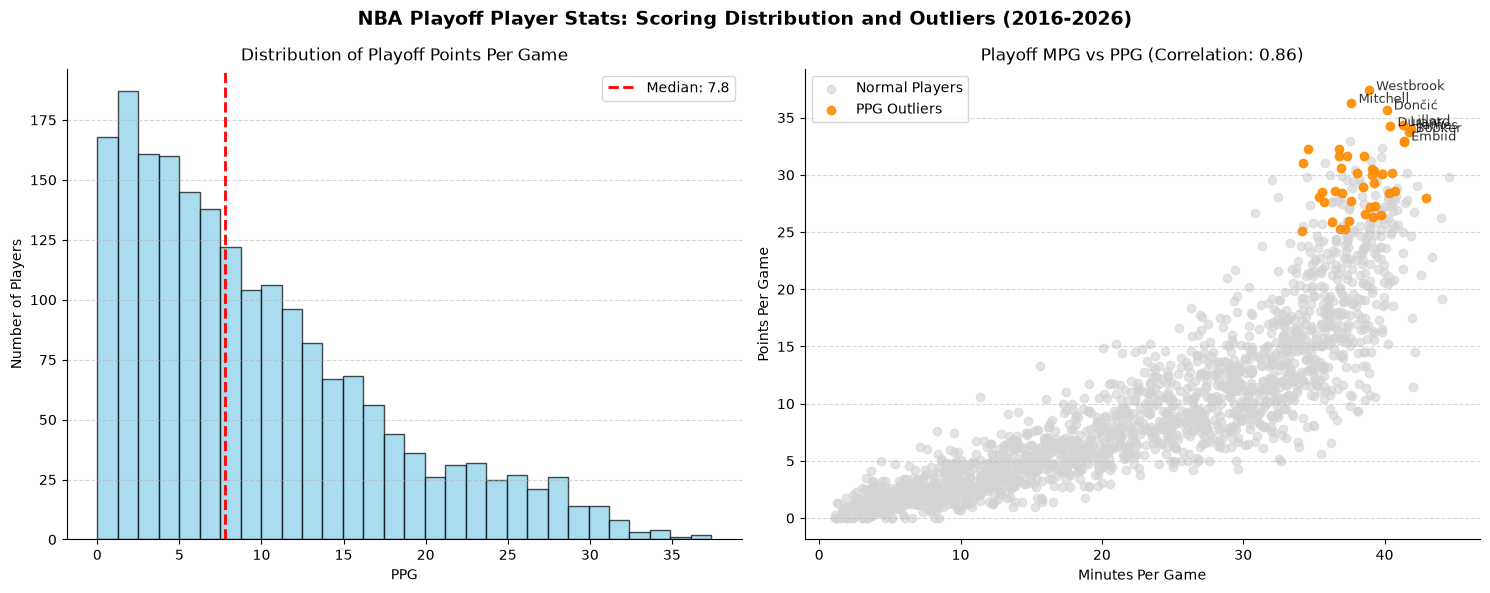

In [11]:
display(df_playoffs_clean[stat_cols].describe().round(3))

po_corr_val = df_playoffs_clean['mpg'].corr(df_playoffs_clean['ppg'])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].hist(df_playoffs_clean['ppg'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
po_median_ppg = df_playoffs_clean['ppg'].median()
axes[0].axvline(po_median_ppg, color='red', linestyle='--', linewidth=2, label=f'Median: {po_median_ppg:.1f}')
axes[0].set_title('Distribution of Playoff Points Per Game')
axes[0].set_xlabel('PPG')
axes[0].set_ylabel('Number of Players')
axes[0].legend()

po_normal = df_playoffs_clean[~df_playoffs_clean['ppg_outlier']]
po_outliers = df_playoffs_clean[df_playoffs_clean['ppg_outlier']]
axes[1].scatter(po_normal['mpg'], po_normal['ppg'], color='lightgray', alpha=0.6, label='Normal Players')
axes[1].scatter(po_outliers['mpg'], po_outliers['ppg'], color='darkorange', alpha=0.9, label='PPG Outliers')
for _, row in po_outliers.sort_values('ppg', ascending=False).head(8).iterrows():
    axes[1].text(row['mpg'] + 0.5, row['ppg'], row['player_name'].split()[-1], fontsize=9, alpha=0.8)
axes[1].set_title(f'Playoff MPG vs PPG (Correlation: {po_corr_val:.2f})')
axes[1].set_xlabel('Minutes Per Game')
axes[1].set_ylabel('Points Per Game')
axes[1].legend()

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('NBA Playoff Player Stats: Scoring Distribution and Outliers (2016-2026)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### What we found
* **Typical scoring:** The middle value is 7.8 playoff points per game, compared with 7.7 in the cleaned regular-season table. This doesn't mean players score the same in the playoffs: the two tables contain different players (only playoff teams, and coaches shorten their rotations). Section 5I compares the **same** players.
* **Minutes and points go together:** The correlation between `mpg` and `ppg` is 0.86 in the playoffs, compared with 0.88 in the regular season.
* **Outliers:** After the `gp >= 4` filter, 43 player-postseasons are scoring outliers (IQR rule within each postseason). They are the playoffs' top scorers, and we keep them.

### Regular season vs playoffs: same players
Comparing the two whole tables is misleading, because the playoff table contains only players on good teams.
So we pair each player's playoff row with **his own** regular-season row from the same season, and look at how his stats change.
Both rows must pass their games filter (`gp >= 10` regular season, `gp >= 4` playoffs).

**Points per 36 minutes** separates "scores more because he plays more" from "scores more per minute on the floor".

Player-seasons in both cleaned tables: 1,945


,regular_season_avg,playoffs_avg,avg_change,pct_players_up
mpg,23.557,22.363,-1.194,46.992
ppg,11.110,9.771,-1.339,31.362
rpg,4.324,3.940,-0.383,38.252
apg,2.480,2.042,-0.438,25.604
bpg,0.482,0.429,-0.053,36.504
spg,0.770,0.659,-0.110,32.956
ts_pct,0.572,0.541,-0.031,35.784
plus_minus,1.783,-1.285,-3.068,28.535
pts36,15.960,14.304,-1.656,30.180


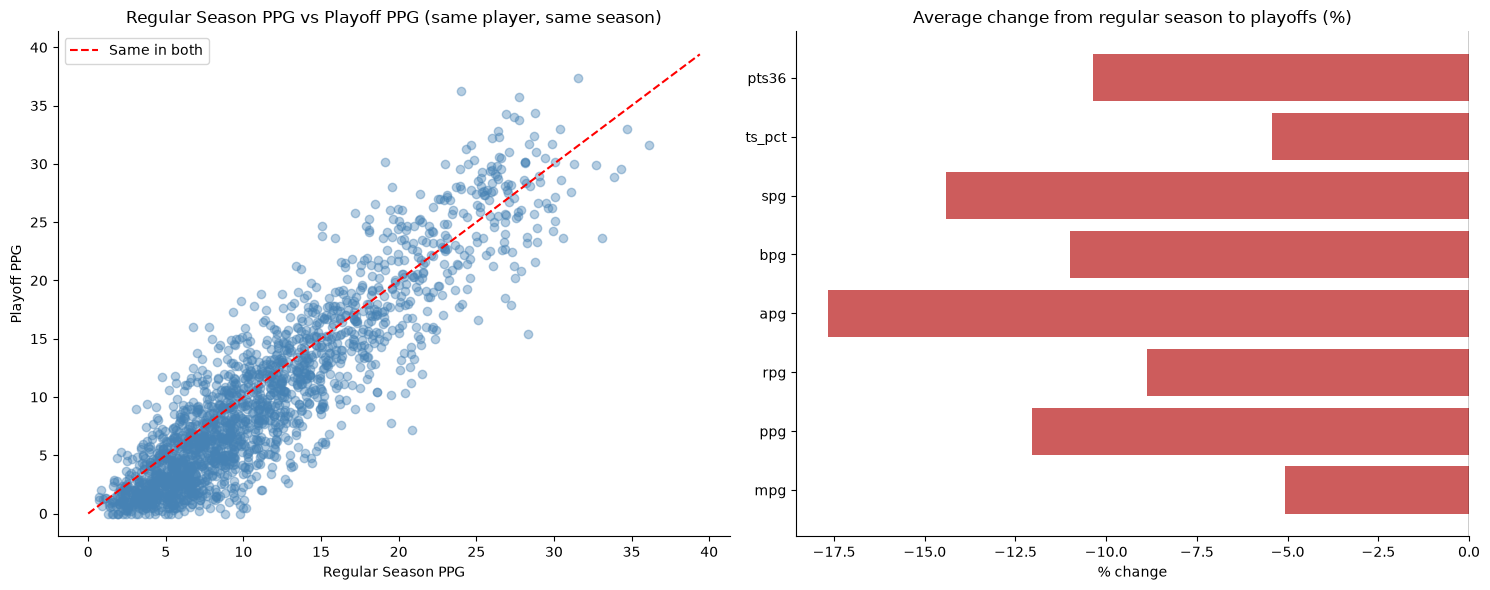

In [12]:
compare_cols = ['mpg', 'ppg', 'rpg', 'apg', 'bpg', 'spg', 'ts_pct', 'plus_minus']
paired = df_regular_clean.merge(df_playoffs_clean, on=['player_id', 'season'], suffixes=('_rs', '_po'))
for side in ['rs', 'po']:
    paired[f'pts36_{side}'] = paired[f'ppg_{side}'] / paired[f'mpg_{side}'] * 36
compare_cols.append('pts36')

comparison = pd.DataFrame({
    'regular_season_avg': [paired[f'{c}_rs'].mean() for c in compare_cols],
    'playoffs_avg': [paired[f'{c}_po'].mean() for c in compare_cols],
    'avg_change': [(paired[f'{c}_po'] - paired[f'{c}_rs']).mean() for c in compare_cols],
    'pct_players_up': [(paired[f'{c}_po'] > paired[f'{c}_rs']).mean() * 100 for c in compare_cols],
}, index=compare_cols).round(3)
print(f"Player-seasons in both cleaned tables: {len(paired):,}")
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(paired['ppg_rs'], paired['ppg_po'], alpha=0.4, color='steelblue')
lim = max(paired['ppg_rs'].max(), paired['ppg_po'].max()) + 2
axes[0].plot([0, lim], [0, lim], color='red', linestyle='--', label='Same in both')
axes[0].set_title('Regular Season PPG vs Playoff PPG (same player, same season)')
axes[0].set_xlabel('Regular Season PPG')
axes[0].set_ylabel('Playoff PPG')
axes[0].legend()

pct_change = ((comparison['playoffs_avg'] - comparison['regular_season_avg'])
              / comparison['regular_season_avg'].abs() * 100).drop('plus_minus')
axes[1].barh(pct_change.index, pct_change.values,
             color=['seagreen' if v > 0 else 'indianred' for v in pct_change.values])
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Average change from regular season to playoffs (%)')
axes[1].set_xlabel('% change')
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

### What we found
Based on 1,945 player-seasons where the same player passes the games filter in both the regular season and the playoffs:
* **Scoring drops:** Points per game fall from 11.11 to 9.77 on average, and only 31% of players score more in the playoffs.
* **The drop comes from scoring less per minute, not from playing less:** Points per 36 minutes fall from 15.96 to 14.30 (about 10%), while minutes per game fall only from 23.56 to 22.36 (about 5%). 47% of players play more minutes in the playoffs, so rotations shift rather than shrink across the board.
* **Shooting efficiency drops:** True shooting falls from 57.2% to 54.1%, and only 36% of players shoot better. This fits playoff defenses being better and more prepared, since every opponent is a good team.
* **Every other stat also drops on average:** Rebounds fall from 4.32 to 3.94, assists from 2.48 to 2.04, blocks from 0.48 to 0.43 and steals from 0.77 to 0.66.
* **Plus/minus falls from +1.78 to −1.28:** In the regular season these players are mostly on good teams beating weaker ones. In the playoffs, half of all games are losses against other good teams. So this change mostly reflects the competition, not the player.

**Caveat:** this only covers players whose teams made the playoffs, so it describes how good-team players change, not every player.

### Notes on how the data was built
Points to keep in mind when using either cleaned table:
* **Missing trend values are left blank on purpose.** A trend can only be calculated when a player has 3 seasons in a row, so it's blank for rookies, players who missed a season, and, in the playoffs, anyone whose team didn't make three straight postseasons. That's **37% of the regular-season table and 70% of the raw playoff table** (1,685 of 2,405 rows; after cleaning, 654 of 1,974 playoff rows have a trend). We don't fill these values: filling with 0 or an average would invent a history the player doesn't have, and dropping the rows would throw away real playoff stats. The `full_3yr_window` column marks which rows have a trend, so any analysis of trends should filter to `full_3yr_window == True`.
* **`trend_3yr_*` columns are 3-season averages, not trends.** They're the average of this season and the two before it, so they smooth out a player's level but don't show whether he's improving or declining. A player going 30 → 25 → 20 PPG and one going 20 → 25 → 30 both get 25. To measure direction, use the change per season (in DuckDB: `REGR_SLOPE(ppg, season) OVER w3`).
* **Playoff trends use playoff seasons only** and need three postseasons in a row, so most are blank.
* **`plus_minus` is on-court plus/minus per game**, not Box Plus/Minus (BPM). It depends on teammates and opponents. The database has no BPM; `openrapm` has an adjusted impact rating, but only for the regular season.
* **`years_in_nba`** is counted from the draft year. It overcounts players who were drafted but joined the league later (draft-and-stash picks).
* **Traded players** have one combined row per season in the source table (checked with Luka Dončić, 2024-25: one row, 50 games), so their stats are not double-counted. Their `gp` can go above 82 (e.g. Mikal Bridges, 83 in 2022-23) because they can join a team that has more games left. That's real, not an error.
* **Play-in games** are in neither table. The database has only `regular_season` and `playoffs`, and Curry and DeRozan (who lost in the 2023-24 play-in) have no playoff row.